Machine operating conditions
        ↓
Failure detected
        ↓
Fault Diagnosis Model
        ↓
Possible failure type(s)

TWF → Tool Wear Failure
HDF → Heat Dissipation Failure
PWF → Power Failure
OSF → Overstrain Failure
RNF → Random Failure

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../data/raw/ai4i2020.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


Define legitimate inputs and diagnosis targets

In [4]:
features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

fault_targets = [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

X = df[features].copy()
Y = df[fault_targets].copy()

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (10000, 6)
Y shape: (10000, 5)


Understand each target

In [5]:
fault_summary = pd.DataFrame({
    "Positive Samples": Y.sum(),
    "Negative Samples": len(Y) - Y.sum(),
    "Positive Percentage": Y.mean() * 100
})

fault_summary

,Positive Samples,Negative Samples,Positive Percentage
TWF,46,9954,0.46
HDF,115,9885,1.15
PWF,95,9905,0.95
OSF,98,9902,0.98
RNF,19,9981,0.19


Visualize fault frequencies

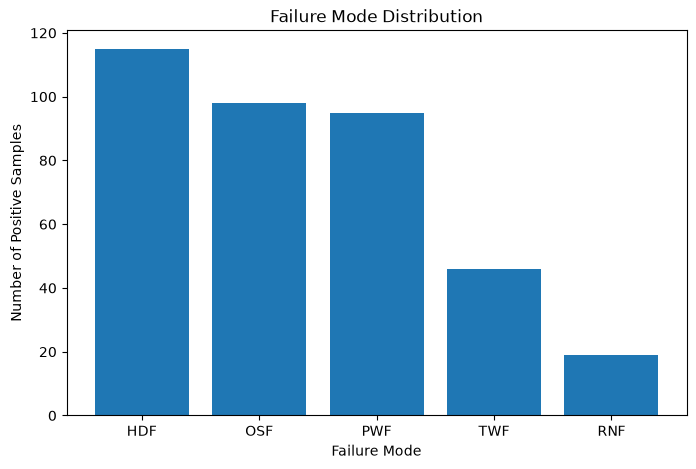

In [6]:
fault_counts = Y.sum().sort_values(
    ascending=False
)

plt.figure(figsize=(8, 5))

plt.bar(
    fault_counts.index,
    fault_counts.values
)

plt.title("Failure Mode Distribution")
plt.xlabel("Failure Mode")
plt.ylabel("Number of Positive Samples")

plt.show()

Check simultaneous failures

In [7]:
fault_count_per_row = Y.sum(axis=1)

print(
    fault_count_per_row.value_counts().sort_index()
)

0    9652
1     324
2      23
3       1
Name: count, dtype: int64


Check fault combinations

In [8]:
fault_combinations = (
    Y.astype(str)
     .agg("-".join, axis=1)
     .value_counts()
)

fault_combinations.head(15)

0-0-0-0-0    9652
0-1-0-0-0     106
0-0-1-0-0      80
0-0-0-1-0      78
1-0-0-0-0      42
0-0-0-0-1      18
0-0-1-1-0      11
0-1-0-1-0       6
0-1-1-0-0       3
1-0-0-1-0       2
1-0-0-0-1       1
1-0-1-1-0       1
Name: count, dtype: int64

Check feature means for each fault

In [9]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

for fault in fault_targets:

    print("\n" + "=" * 60)
    print(f"FAULT: {fault}")
    print("=" * 60)

    comparison = (
        df.groupby(fault)[numeric_features]
          .mean()
          .T
    )

    print(comparison)


FAULT: TWF
TWF                                0            1
Air temperature [K]       300.003576   300.297826
Process temperature [K]   310.004822   310.165217
Rotational speed [rpm]   1538.649488  1566.173913
Torque [Nm]                39.996845    37.836957
Tool wear [min]           107.449970   216.369565

FAULT: HDF
HDF                                0            1
Air temperature [K]       299.975195   302.560870
Process temperature [K]   309.996449   310.788696
Rotational speed [rpm]   1541.120486  1337.260870
Torque [Nm]                39.833576    53.166957
Tool wear [min]           107.959838   107.191304

FAULT: PWF
PWF                                0            1
Air temperature [K]       300.004250   300.075789
Process temperature [K]   310.006047   309.954737
Rotational speed [rpm]   1536.616254  1763.968421
Torque [Nm]                39.905119    48.514737
Tool wear [min]           108.009187   101.884211

FAULT: OSF
OSF                                0            1
Ai

Important RNF decision

In [10]:
print("RNF positive samples:")
print(df[df["RNF"] == 1][features])

print(
    "\nTotal RNF positives:",
    df["RNF"].sum()
)

RNF positive samples:
     Type  Air temperature [K]  Process temperature [K]  \
1221    M                297.0                    308.3   
1302    L                298.6                    309.8   
1748    H                298.4                    307.7   
2072    L                299.6                    309.5   
2559    L                299.3                    309.0   
3065    M                300.1                    309.2   
3452    H                301.6                    310.5   
3611    L                301.7                    310.9   
5471    L                302.7                    312.3   
5489    L                302.6                    312.1   
5495    H                302.9                    312.5   
5509    L                302.8                    312.2   
5553    L                302.5                    311.9   
5639    L                302.6                    312.1   
6091    L                300.9                    310.7   
6913    L                300.8    

Only 19 positive observations means a normal supervised model for RNF will be statistically fragile.
So I do not want us to force a seemingly impressive RNF model.
In the project we can potentially report:
RNF is retained as an exploratory target, but reliable supervised learning is constrained by the extremely small number of positive examples.

That is scientifically much better than manufacturing a misleading 99.9% accuracy.

Prepare preprocessing

In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [12]:
categorical_features = [
    "Type"
]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


Prepare 5-fold CV

In [13]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation ready!")

Cross-validation ready!


Import XGBoost and CV tools

In [14]:
from xgboost import XGBClassifier

from sklearn.model_selection import cross_validate

print("XGBoost and CV tools imported!")

XGBoost and CV tools imported!


Create a function for one fault

In [15]:
def create_fault_pipeline(y_fault):

    negative_count = (y_fault == 0).sum()
    positive_count = (y_fault == 1).sum()

    scale_pos_weight = (
        negative_count / positive_count
    )

    model = XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    return pipeline, scale_pos_weight

Define evaluation metrics

In [16]:
fault_scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

Cross-validate each fault separately

In [17]:
fault_results = []

for fault in fault_targets:

    print("\nEvaluating:", fault)

    y_fault = Y[fault]

    pipeline, weight = create_fault_pipeline(
        y_fault
    )

    scores = cross_validate(
        pipeline,
        X,
        y_fault,
        cv=cv,
        scoring=fault_scoring,
        n_jobs=-1
    )

    fault_results.append({
        "Fault": fault,
        "Positive Samples": int(y_fault.sum()),
        "Scale Pos Weight": weight,

        "Precision Mean":
            scores["test_precision"].mean(),

        "Precision Std":
            scores["test_precision"].std(),

        "Recall Mean":
            scores["test_recall"].mean(),

        "Recall Std":
            scores["test_recall"].std(),

        "F1 Mean":
            scores["test_f1"].mean(),

        "F1 Std":
            scores["test_f1"].std(),

        "ROC-AUC Mean":
            scores["test_roc_auc"].mean(),

        "PR-AUC Mean":
            scores["test_pr_auc"].mean()
    })

print("\nCross-validation completed!")


Evaluating: TWF

Evaluating: HDF

Evaluating: PWF

Evaluating: OSF

Evaluating: RNF

Cross-validation completed!


Create results table

In [18]:
fault_results_df = pd.DataFrame(
    fault_results
)

fault_results_df.round(4)

,Fault,Positive Samples,Scale Pos Weight,Precision Mean,Precision Std,Recall Mean,Recall Std,F1 Mean,F1 Std,ROC-AUC Mean,PR-AUC Mean
0,TWF,46,216.3913,0.0787,0.0447,0.1756,0.1345,0.1077,0.0677,0.9560,0.1001
1,HDF,115,85.9565,0.8861,0.0546,0.9652,0.0325,0.9219,0.0163,0.9988,0.9804
2,PWF,95,104.2632,0.6721,0.0503,0.8316,0.0516,0.7422,0.0418,0.9953,0.7876
3,OSF,98,101.0408,0.7893,0.0461,0.9384,0.0384,0.8565,0.0328,0.9992,0.9533
4,RNF,19,525.3158,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.4912,0.0069


Add a random-baseline PR-AUC

In [19]:
fault_results_df["Random PR Baseline"] = (
    fault_results_df["Positive Samples"] / len(df)
)

fault_results_df[
    [
        "Fault",
        "Positive Samples",
        "Precision Mean",
        "Recall Mean",
        "F1 Mean",
        "PR-AUC Mean",
        "Random PR Baseline"
    ]
].round(4)

,Fault,Positive Samples,Precision Mean,Recall Mean,F1 Mean,PR-AUC Mean,Random PR Baseline
0,TWF,46,0.0787,0.1756,0.1077,0.1001,0.0046
1,HDF,115,0.8861,0.9652,0.9219,0.9804,0.0115
2,PWF,95,0.6721,0.8316,0.7422,0.7876,0.0095
3,OSF,98,0.7893,0.9384,0.8565,0.9533,0.0098
4,RNF,19,0.0000,0.0000,0.0000,0.0069,0.0019


What this means for the project
We should not delete TWF or RNF from the dataset, and we should not manipulate the data just to make their metrics look better.
Instead, our diagnosis architecture should reflect the evidence:
                  Machine operating data
                           │
          ┌────────────────┼─────────────────┐
          ↓                ↓                 ↓
         HDF              PWF               OSF
       STRONG            GOOD              STRONG
          │                │                 │
          └────────────────┼─────────────────┘
                           ↓
                  Fault Diagnosis
                           
TWF → Experimental / low-confidence
RNF → Insufficient data for reliable supervised diagnosis

This is actually more credible for your project than claiming 99% performance everywhere.
Why HDF and OSF are so predictable
AI4I's failure modes are partly generated from relationships involving the same physical operating variables available to the model. For example, heat-dissipation, power, overstrain and tool-wear failures have structured relationships with temperature, speed, torque and wear. So strong results for some modes are expected.
This is also why we must describe this as performance on the AI4I benchmark, not proof that the same accuracy will occur in a real petrochemical plant.

Generate out-of-fold probabilities for TWF

In [20]:
from sklearn.model_selection import cross_val_predict

In [21]:
twf_y = Y["TWF"]

twf_pipeline, twf_weight = create_fault_pipeline(
    twf_y
)

twf_oof_prob = cross_val_predict(
    twf_pipeline,
    X,
    twf_y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("TWF OOF probabilities created.")

TWF OOF probabilities created.


Analyze TWF thresholds

In [22]:
twf_threshold_results = []

for threshold in np.arange(0.05, 0.951, 0.01):

    pred = (
        twf_oof_prob >= threshold
    ).astype(int)

    twf_threshold_results.append({
        "Threshold": threshold,

        "Precision": precision_score(
            twf_y,
            pred,
            zero_division=0
        ),

        "Recall": recall_score(
            twf_y,
            pred,
            zero_division=0
        ),

        "F1": f1_score(
            twf_y,
            pred,
            zero_division=0
        )
    })

twf_threshold_df = pd.DataFrame(
    twf_threshold_results
)

best_twf = twf_threshold_df.loc[
    twf_threshold_df["F1"].idxmax()
]

print("Best TWF threshold:")
print(best_twf)

Best TWF threshold:
Threshold    0.570000
Precision    0.106667
Recall       0.173913
F1           0.132231
Name: 52, dtype: float64


In [23]:
twf_threshold_df.sort_values(
    "F1",
    ascending=False
).head(10)


,Threshold,Precision,Recall,F1
52,0.57,0.106667,0.173913,0.132231
53,0.58,0.106667,0.173913,0.132231
51,0.56,0.102564,0.173913,0.129032
50,0.55,0.102564,0.173913,0.129032
58,0.63,0.107692,0.152174,0.126126
49,0.54,0.098765,0.173913,0.125984
57,0.62,0.106061,0.152174,0.125000
48,0.53,0.094118,0.173913,0.122137
56,0.61,0.101449,0.152174,0.121739
55,0.60,0.101449,0.152174,0.121739


This tells us whether TWF's main problem is simply the default threshold or whether the classifier itself has weak separation.

That's still too weak to present TWF as a reliable diagnostic classifier.
Why?
The biggest problem is the dataset:
TWF positive samples = 46
TWF negative samples = 9,954

Only 0.46% are TWF.

HDF → Reliable candidate       ✅
PWF → Useful candidate         ✅
OSF → Reliable candidate       ✅

TWF → Experimental / low confidence ⚠️
RNF → Insufficient evidence        ❌

Function for final model evaluation

In [24]:
from sklearn.model_selection import train_test_split

def train_evaluate_fault(fault_name):

    y_fault = Y[fault_name]

    X_train_fault, X_test_fault, y_train_fault, y_test_fault = (
        train_test_split(
            X,
            y_fault,
            test_size=0.20,
            random_state=42,
            stratify=y_fault
        )
    )

    pipeline, weight = create_fault_pipeline(
        y_train_fault
    )

    pipeline.fit(
        X_train_fault,
        y_train_fault
    )

    probabilities = pipeline.predict_proba(
        X_test_fault
    )[:, 1]

    predictions = (
        probabilities >= 0.50
    ).astype(int)

    results = {
        "Fault": fault_name,
        "Test Positives": int(y_test_fault.sum()),

        "Precision": precision_score(
            y_test_fault,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test_fault,
            predictions,
            zero_division=0
        ),

        "F1": f1_score(
            y_test_fault,
            predictions,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test_fault,
            probabilities
        ),

        "PR-AUC": average_precision_score(
            y_test_fault,
            probabilities
        )
    }

    return pipeline, results, (
        X_test_fault,
        y_test_fault,
        probabilities,
        predictions
    )

Train HDF, PWF and OSF

In [25]:
diagnosis_models = {}
diagnosis_results = []
diagnosis_test_data = {}

for fault in ["HDF", "PWF", "OSF"]:

    model, result, test_data = (
        train_evaluate_fault(fault)
    )

    diagnosis_models[fault] = model
    diagnosis_results.append(result)
    diagnosis_test_data[fault] = test_data

final_diagnosis_results = pd.DataFrame(
    diagnosis_results
)

final_diagnosis_results.round(4)

,Fault,Test Positives,Precision,Recall,F1,ROC-AUC,PR-AUC
0,HDF,23,0.9545,0.9130,0.9333,0.9941,0.9448
1,PWF,19,0.6429,0.9474,0.7660,0.9984,0.8269
2,OSF,20,0.7727,0.8500,0.8095,0.9987,0.9255


Get confusion matrices

In [26]:
for fault in ["HDF", "PWF", "OSF"]:

    X_test_fault, y_test_fault, probabilities, predictions = (
        diagnosis_test_data[fault]
    )

    cm = confusion_matrix(
        y_test_fault,
        predictions
    )

    tn, fp, fn, tp = cm.ravel()

    print("\n", "=" * 40)
    print(fault)
    print("=" * 40)

    print("TN:", tn)
    print("FP:", fp)
    print("FN:", fn)
    print("TP:", tp)


HDF
TN: 1976
FP: 1
FN: 2
TP: 21

PWF
TN: 1971
FP: 10
FN: 1
TP: 18

OSF
TN: 1975
FP: 5
FN: 3
TP: 17


Therefore, even these held-out estimates have uncertainty. We should mention that limitation in the final report.

HDF is excellent: 21 of 23 HDF events detected, only 1 false alarm, and 2 missed.
PWF strongly favors recall: 18 of 19 failures detected, but with 10 false positives. For predictive maintenance, that can be a reasonable starting operating point because only one actual PWF event was missed.
OSF is also strong: 17 of 20 detected, with 5 false alarms and 3 missed.
One caution: each test set contains only 19–23 positive cases, so these percentages have substantial sampling uncertainty. In the final report, present the raw counts alongside percentages.
Important correction before saving the models
The three models currently stored in diagnosis_models were trained on only 80% of the data.
Now that evaluation is finished, we should retrain the deployable versions on all 10,000 observations.
The test results remain our evaluation results. Retraining afterward is for deployment.

Train final deployment models

In [27]:
final_diagnosis_models = {}

for fault in ["HDF", "PWF", "OSF"]:

    print(f"Training final {fault} model...")

    y_fault = Y[fault]

    pipeline, weight = create_fault_pipeline(
        y_fault
    )

    pipeline.fit(
        X,
        y_fault
    )

    final_diagnosis_models[fault] = pipeline

print("\nAll final diagnosis models trained!")

Training final HDF model...
Training final PWF model...
Training final OSF model...

All final diagnosis models trained!


Save all three models

In [28]:
import joblib

joblib.dump(
    final_diagnosis_models["HDF"],
    "../models/diagnosis_hdf.joblib"
)

joblib.dump(
    final_diagnosis_models["PWF"],
    "../models/diagnosis_pwf.joblib"
)

joblib.dump(
    final_diagnosis_models["OSF"],
    "../models/diagnosis_osf.joblib"
)

print("Diagnosis models saved successfully!")

Diagnosis models saved successfully!


Save diagnosis configuration

In [29]:
import json

diagnosis_config = {
    "supported_faults": {
        "HDF": {
            "name": "Heat Dissipation Failure",
            "threshold": 0.50
        },

        "PWF": {
            "name": "Power Failure",
            "threshold": 0.50
        },

        "OSF": {
            "name": "Overstrain Failure",
            "threshold": 0.50
        }
    },

    "experimental_faults": {
        "TWF": {
            "name": "Tool Wear Failure",
            "reason": "Low predictive performance and only 46 positive samples"
        }
    },

    "unsupported_faults": {
        "RNF": {
            "name": "Random Failure",
            "reason": "Only 19 positive samples; insufficient evidence for reliable supervised diagnosis"
        }
    },

    "features": [
        "Type",
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
}

with open(
    "../models/diagnosis_config.json",
    "w"
) as file:

    json.dump(
        diagnosis_config,
        file,
        indent=4
    )

print("Diagnosis configuration saved!")

Diagnosis configuration saved!


Verify saved models

In [30]:
hdf_model = joblib.load(
    "../models/diagnosis_hdf.joblib"
)

pwf_model = joblib.load(
    "../models/diagnosis_pwf.joblib"
)

osf_model = joblib.load(
    "../models/diagnosis_osf.joblib"
)

print("All models loaded successfully!")

All models loaded successfully!


Then test one machine:

In [31]:
sample_machine = X.iloc[[0]]

print(sample_machine)

print(
    "\nHDF score:",
    hdf_model.predict_proba(sample_machine)[0, 1]
)

print(
    "PWF score:",
    pwf_model.predict_proba(sample_machine)[0, 1]
)

print(
    "OSF score:",
    osf_model.predict_proba(sample_machine)[0, 1]
)

  Type  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    M                298.1                    308.6                    1551   

   Torque [Nm]  Tool wear [min]  
0         42.8                0  

HDF score: 1.5886848e-05
PWF score: 0.00014565742
OSF score: 1.9838005e-06
